# Naloga

---
## Analitični del

Za sistem izberemo normirane parametre iz učbenika: $a = 1{,}0$, $b = 1{,}0$ ter dušenje $d = 0{,}3$.

1. Zapišite sistem dveh diferencialnih enačb prvega reda za $x$ in $v = \dot{x}$:

   $\dot{x} =$ ____________________  $\dot{v} =$ ______________________________

2. Določite numerične koordinate vseh treh stacionarnih točk $(x^{\ast}, v^{\ast})$ v fazni ravnini:

   $T_0^{\ast} = (0, 0)$, $T_1^{\ast} = ($ ______ $, 0)$, $T_2^{\ast} = ($ ______ $, 0)$.

3. Zapišite splošno Jacobijevo matriko sistema $\mathbf{J}(x, v)$ ter jo ovrednotite v točkah $T_0^{\ast}$ in $T_1^{\ast}$:

   $\mathbf{J}(0, 0) =$ __________  $\mathbf{J}(1, 0) =$ __________

4. Za točko $T_1^{\ast} = (1, 0)$ izračunajte sled $\tau$, determinanto $\Delta$ in lastni vrednosti $\lambda_{1,2}$. Določite tip ravnotežja:

   $\tau =$ ______, $\Delta =$ ______ $\implies$ Tip: ____________________

---
## Naloga 1: Profil potenciala in nivojnice energije

1. Izrišite profil potencialne energije $V(x) = -\frac{a}{2}x^2 + \frac{b}{4}x^4$ na območju $x \in [-2, 2]$. Označite oba minimuma in vrh pregrade pri $x=0$.
2. Za primer brez dušenja ($d = 0$) narišite nivojnice skupne mehanske energije $E(x, v) = \frac{1}{2}v^2 + V(x) = \text{konst.}$ v fazni ravnini s funkcijo `matplotlib.pyplot.contour`. Posebej poudarite separatriso z energijo $E = 0$.

## Naloga 2: Fazni portret dušenega sistema in konvergence

1. Vključite dušenje $d = 0{,}3$. Na območju $(x, v) \in [-2, 2] \times [-2, 2]$ izrišite vektorsko polje toka s funkcijo `matplotlib.pyplot.streamplot`.
2. Z numeričnim integratorjem (npr. `scipy.integrate.solve_ivp`) simulirajte časovni odziv za začetna pogoja iz učbenika:
   - Trajektorija A: $(x_0, v_0) = (-1{,}5,\ 0{,}5)$
   - Trajektorija B: $(x_0, v_0) = (1{,}5,\ -0{,}5)$

   Obe trajektoriji vrišite v fazno ravnino in potrdite, da konvergirata vsaka v svoj stabilni jašek.
3. Izrišite časovni potek mehanske energije $E(t)$ in preverite, da se energija monotono zmanjšuje proti $V_{\min} = -0{,}25$.

## Naloga 3: Kartiranje bazenov privlačnosti

Za mrežo začetnih pogojev $(x_0, v_0) \in [-2, 2] \times [-2, 2]$ z ločljivostjo vsaj $100 \times 100$ točk določite končno stanje po dovolj dolgem času integracije ($t_{\text{end}} \approx 30$).

- Če se trajektorija ustali v levem minimumu ($x^{\ast} \approx -1$), točko obarvajte modro.
- Če se trajektorija ustali v desnem minimumu ($x^{\ast} \approx +1$), točko obarvajte rdeče.
- Izrišite dobljeno karto in opazujte mejo med bazenoma, ki poteka skozi sedelno točko $(0,0)$.

| Začetni pogoj $(x_0, v_0)$ | Končna lega $x(\infty)$ | Končna energija $E(\infty)$ | Bazen privlačnosti |
|:-:|:-:|:-:|:-:|
| $(-1{,}5,\ 0{,}5)$ | | | Levi / Desni |
| $(1{,}5,\ -0{,}5)$ | | | Levi / Desni |
| $(0{,}1,\ 0{,}0)$ | | | Levi / Desni |
| $(-0{,}1,\ 0{,}0)$ | | | Levi / Desni |
| $(0{,}0,\ 1{,}2)$ | | | Levi / Desni |

# Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import sympy as sp
from scipy.integrate import solve_ivp

# Global parameters
a, b = 1.0, 1.0
d = 0.3              # dusenje
meja = 2.0           # obmocje [-meja, meja]^2
t_end = 30.0
N_mreza = 200        # locljivost karte bazenov

y_A = [-1.5, 0.5]
y_B = [1.5, -0.5]
tabela_zp = [(-1.5, 0.5), (1.5, -0.5), (0.1, 0.0), (-0.1, 0.0), (0.0, 1.2)]

rtol, atol = 1e-10, 1e-12

# Funkcije

In [3]:
# Simbolno: potencial, sistem 1. reda, ravnotezja, Jacobijeva matrika
x, v = sp.symbols("x v", real=True)
a_s, b_s, d_s = sp.symbols("a b d", positive=True)

V_sym = -a_s / 2 * x**2 + b_s / 4 * x**4
F_sym = -sp.diff(V_sym, x)
f_sym = sp.Matrix([v, F_sym - d_s * v])
J_sym = f_sym.jacobian([x, v])
ravnotezja = sp.solve(list(f_sym), [x, v], dict=True)

par = {a_s: a, b_s: b, d_s: d}
V = sp.lambdify(x, V_sym.subs(par), "numpy")
E = sp.lambdify((x, v), (v**2 / 2 + V_sym).subs(par), "numpy")

In [4]:
def rhs(t, y, d):
    x, v = y
    return [v, a * x - b * x**3 - d * v]

def trajektorija(y0, t_end, d=d, n=3000):
    t_eval = np.linspace(0, t_end, n)
    return solve_ivp(rhs, (0, t_end), y0, args=(d,), t_eval=t_eval, rtol=rtol, atol=atol)

def rk4_mreza(X, Vv, t_end, d=d, dt=0.01):
    # RK4 hkrati za vse tocke mreze (vektorsko)
    def f(X, Vv):
        return Vv, a * X - b * X**3 - d * Vv
    for _ in range(int(t_end / dt)):
        k1x, k1v = f(X, Vv)
        k2x, k2v = f(X + dt / 2 * k1x, Vv + dt / 2 * k1v)
        k3x, k3v = f(X + dt / 2 * k2x, Vv + dt / 2 * k2v)
        k4x, k4v = f(X + dt * k3x, Vv + dt * k3v)
        X = X + dt / 6 * (k1x + 2 * k2x + 2 * k3x + k4x)
        Vv = Vv + dt / 6 * (k1v + 2 * k2v + 2 * k3v + k4v)
    return X, Vv

def klasifikacija(A, eps=1e-12):
    tau, Delta = np.trace(A), np.linalg.det(A)
    D = tau**2 - 4 * Delta
    if Delta < -eps:
        return "sedlo"
    if abs(Delta) < eps:
        return "degenerirano (Delta = 0)"
    if abs(tau) < eps:
        return "center"
    if D > eps:
        return "stabilen vozel" if tau < 0 else "nestabilen vozel"
    if D < -eps:
        return "stabilno gorišče" if tau < 0 else "nestabilno gorišče"
    return "degeneriran vozel"

def stabilna_mnogoterost(d=d, t_max=60.0):
    # integracija nazaj v casu iz sedla vzdolz stabilne lastne smeri
    lam_s = (-d - np.sqrt(d**2 + 4 * a)) / 2
    v_s = np.array([1.0, lam_s]) / np.hypot(1.0, lam_s)

    def izven(t, y, d):
        return 2 * meja - np.max(np.abs(y))
    izven.terminal = True

    veji = []
    for s in (1, -1):
        sol = solve_ivp(rhs, (0, -t_max), s * 1e-6 * v_s, args=(d,), events=izven,
                        rtol=rtol, atol=atol, max_step=0.01)
        veji.append(sol.y)
    return veji

# Testno območje

In [5]:
# Pripravljalna naloga
display(sp.Eq(sp.Matrix([sp.Symbol(r"\dot{x}"), sp.Symbol(r"\dot{v}")]), f_sym.subs(par), evaluate=False))
display(sp.Eq(sp.Symbol("J"), J_sym, evaluate=False))

for r in ravnotezja:
    tocka = {x: r[x].subs(par), v: r[v]}
    J_num = np.array(J_sym.subs(par).subs(tocka), dtype=float)
    lam = np.linalg.eigvals(J_num)
    print(f"T* = ({float(tocka[x]):+.0f}, 0):  J = {J_num.tolist()},  tau = {np.trace(J_num):+.2f}, "
          f"Delta = {np.linalg.det(J_num):+.2f},  lambda = {np.round(lam, 4)}  -> {klasifikacija(J_num)}")
print(f"V_min = {V(np.sqrt(a / b)):.4f}")

Eq(Matrix([
[\dot{x}],
[\dot{v}]]), Matrix([
[                        v],
[-0.3*v - 1.0*x**3 + 1.0*x]]))

Eq(J, Matrix([
[           0,  1],
[a - 3*b*x**2, -d]]))

T* = (+0, 0):  J = [[0.0, 1.0], [1.0, -0.3]],  tau = -0.30, Delta = -1.00,  lambda = [ 0.8612+0.j -1.1612+0.j]  -> sedlo
T* = (-1, 0):  J = [[0.0, 1.0], [-2.0, -0.3]],  tau = -0.30, Delta = +2.00,  lambda = [-0.15+1.4062j -0.15-1.4062j]  -> stabilno gorišče
T* = (+1, 0):  J = [[0.0, 1.0], [-2.0, -0.3]],  tau = -0.30, Delta = +2.00,  lambda = [-0.15+1.4062j -0.15-1.4062j]  -> stabilno gorišče
V_min = -0.2500


# Naloga 1

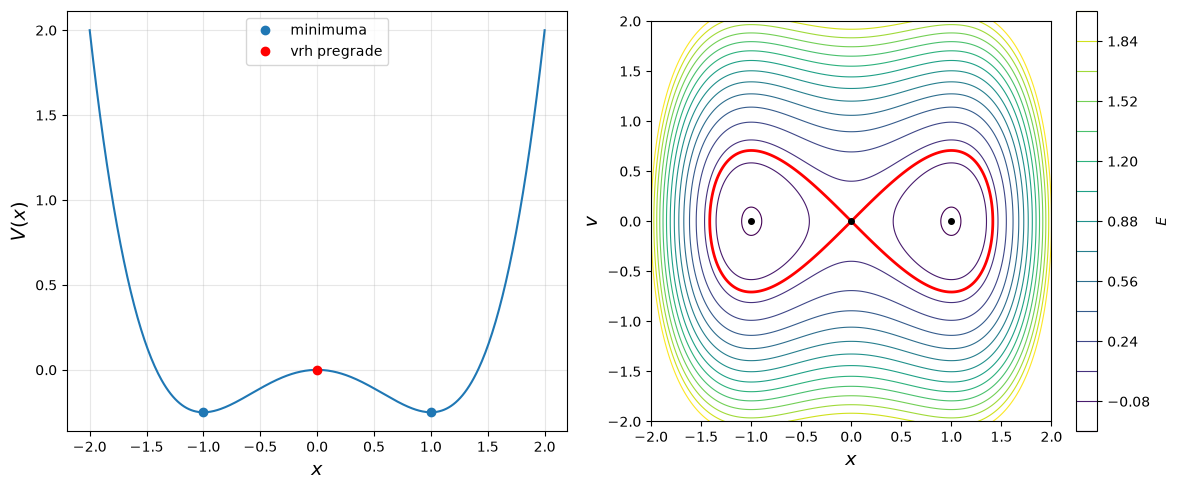

In [6]:
xs = np.linspace(-meja, meja, 400)
x_min = np.sqrt(a / b)

fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(121)
ax.plot(xs, V(xs))
ax.plot([-x_min, x_min], [V(x_min)] * 2, "o", color="C0", label="minimuma")
ax.plot(0, V(0), "o", color="red", label="vrh pregrade")
ax.set_xlabel("$x$", fontsize=14)
ax.set_ylabel("$V(x)$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)

# Nivojnice energije, d = 0
X, Vv = np.meshgrid(xs, xs)
ax = fig.add_subplot(122)
cs = ax.contour(X, Vv, E(X, Vv), levels=np.linspace(-0.24, 2.0, 15), cmap="viridis", linewidths=0.8)
ax.contour(X, Vv, E(X, Vv), levels=[0.0], colors="red", linewidths=2)
ax.plot([-x_min, 0, x_min], [0, 0, 0], "o", color="black", markersize=4)
fig.colorbar(cs, ax=ax, label="$E$")
ax.set_xlabel("$x$", fontsize=14)
ax.set_ylabel("$v$", fontsize=14)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

# Naloga 2

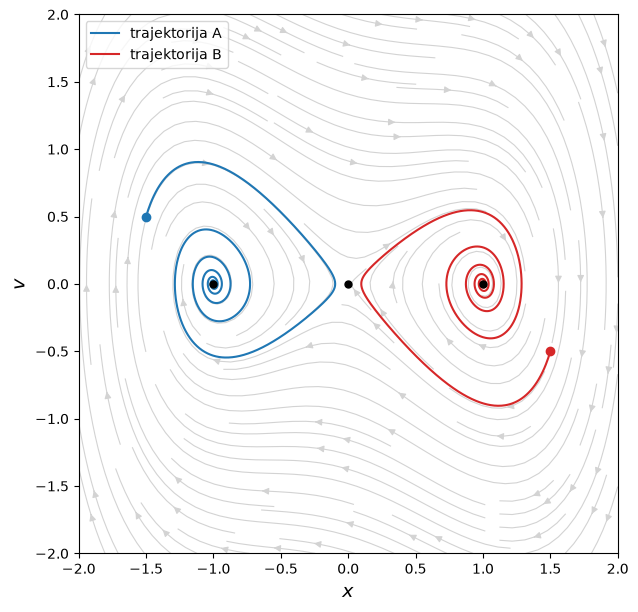

In [7]:
U = Vv
W = a * X - b * X**3 - d * Vv

sol_A = trajektorija(y_A, t_end)
sol_B = trajektorija(y_B, t_end)

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111)
ax.streamplot(X, Vv, U, W, color="lightgray", density=1.4, linewidth=0.8)
for sol, ime, c in [(sol_A, "A", "C0"), (sol_B, "B", "C3")]:
    ax.plot(sol.y[0], sol.y[1], color=c, linewidth=1.5, label=f"trajektorija {ime}")
    ax.plot(*sol.y[:, 0], "o", color=c)
ax.plot([-x_min, 0, x_min], [0, 0, 0], "o", color="black", markersize=5)
ax.set_xlim(-meja, meja)
ax.set_ylim(-meja, meja)
ax.set_aspect("equal")
ax.set_xlabel("$x$", fontsize=14)
ax.set_ylabel("$v$", fontsize=14)
ax.legend(loc="upper left")
plt.show()

A: E(0) = +0.2656, E(t_end) = -0.249863, max dE = -4.9e-11
B: E(0) = +0.2656, E(t_end) = -0.249863, max dE = -4.9e-11


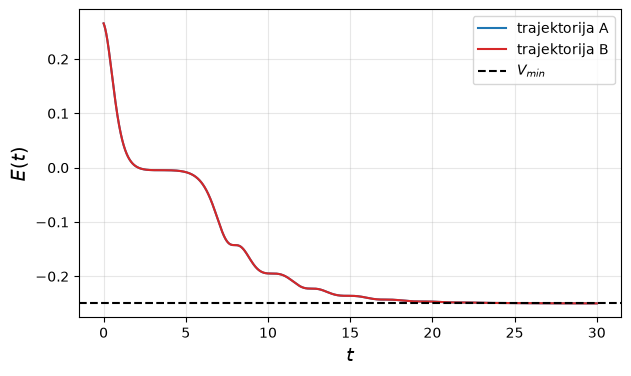

In [8]:
fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
for sol, ime, c in [(sol_A, "A", "C0"), (sol_B, "B", "C3")]:
    E_t = E(sol.y[0], sol.y[1])
    ax.plot(sol.t, E_t, color=c, label=f"trajektorija {ime}")
    print(f"{ime}: E(0) = {E_t[0]:+.4f}, E(t_end) = {E_t[-1]:+.6f}, "
          f"max dE = {np.max(np.diff(E_t)):+.1e}")
ax.axhline(V(x_min), color="black", linestyle="--", label=r"$V_{min}$")
ax.set_xlabel("$t$", fontsize=14)
ax.set_ylabel("$E(t)$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Naloga 3

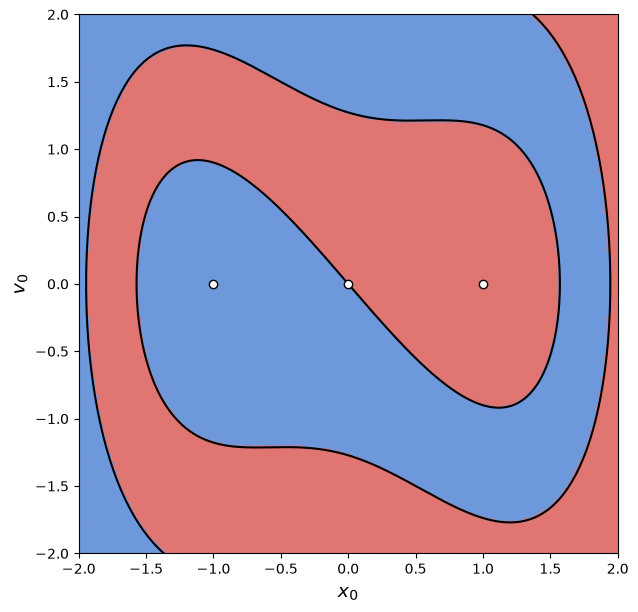

In [9]:
x0s = np.linspace(-meja, meja, N_mreza)
X0, V0 = np.meshgrid(x0s, x0s)
X_end, _ = rk4_mreza(X0, V0, t_end)
bazen = (X_end > 0).astype(int)   # 0 = levi, 1 = desni

veji = stabilna_mnogoterost()

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111)
ax.imshow(bazen, origin="lower", extent=[-meja, meja, -meja, meja],
          cmap=ListedColormap(["#4a7fd4", "#d9534f"]), alpha=0.8)
for y in veji:
    ax.plot(y[0], y[1], color="black", linewidth=1.5)
ax.plot([-x_min, 0, x_min], [0, 0, 0], "o", color="white", markeredgecolor="black")
ax.set_xlim(-meja, meja)
ax.set_ylim(-meja, meja)
ax.set_xlabel("$x_0$", fontsize=14)
ax.set_ylabel("$v_0$", fontsize=14)
plt.show()

In [10]:
print(f"{'(x0, v0)':>14} {'x(inf)':>8} {'E(inf)':>9}  bazen")
for y0 in tabela_zp:
    sol = trajektorija(list(y0), 100.0)
    x_k, v_k = sol.y[:, -1]
    print(f"{str(y0):>14} {x_k:+8.4f} {E(x_k, v_k):+9.5f}  {'desni' if x_k > 0 else 'levi'}")

      (x0, v0)   x(inf)    E(inf)  bazen
   (-1.5, 0.5)  -1.0000  -0.25000  levi
   (1.5, -0.5)  +1.0000  -0.25000  desni
    (0.1, 0.0)  +1.0000  -0.25000  desni
   (-0.1, 0.0)  -1.0000  -0.25000  levi
    (0.0, 1.2)  +1.0000  -0.25000  desni


# Razmislek 1

In [11]:
# Minimalna v0 v (-1, 0), da delec preskoci pregrado (doseze x = 0), bisekcija
def vrh(t, y, d):
    return y[0]
vrh.terminal = True

def preskok(v0, d):
    sol = solve_ivp(rhs, (0, 50), [-x_min, v0], args=(d,), events=vrh, rtol=rtol, atol=atol)
    return sol.status == 1

def v0_min(d, lo=0.0, hi=3.0, tol=1e-6):
    while hi - lo > tol:
        mid = 0.5 * (lo + hi)
        lo, hi = (lo, mid) if preskok(mid, d) else (mid, hi)
    return hi

dV = V(0) - V(x_min)
print(f"d = 0 (analiticno): K_min = dV = {dV:.4f},  v0_min = {np.sqrt(2 * dV):.4f}")

d_list = [0.05, 0.1, 0.2, 0.3, 0.5, 1.0]
K_list = []
for dd in d_list:
    v_m = v0_min(dd)
    K_list.append(v_m**2 / 2)
    print(f"d = {dd:4.2f}: v0_min = {v_m:.4f},  K_min = {v_m**2 / 2:.4f}")

d = 0 (analiticno): K_min = dV = 0.2500,  v0_min = 0.7071
d = 0.05: v0_min = 0.7379,  K_min = 0.2722
d = 0.10: v0_min = 0.7693,  K_min = 0.2959
d = 0.20: v0_min = 0.8338,  K_min = 0.3476
d = 0.30: v0_min = 0.9005,  K_min = 0.4055
d = 0.50: v0_min = 1.0404,  K_min = 0.5413
d = 1.00: v0_min = 1.4221,  K_min = 1.0112


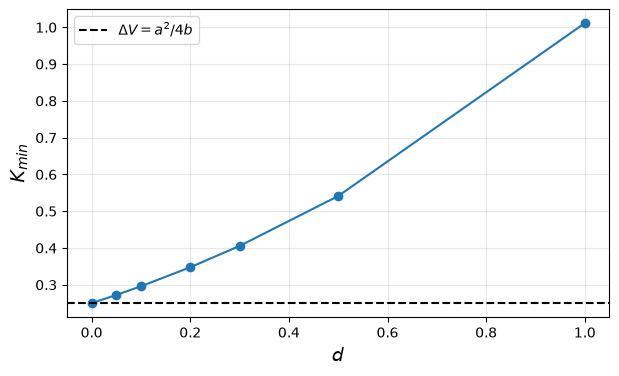

In [12]:
fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
ax.plot([0] + d_list, [dV] + K_list, "o-")
ax.axhline(dV, color="black", linestyle="--", label=r"$\Delta V = a^2/4b$")
ax.set_xlabel("$d$", fontsize=14)
ax.set_ylabel(r"$K_{min}$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Razmislek 2

zacetna tocka na meji: (+1.1941, -0.9092)


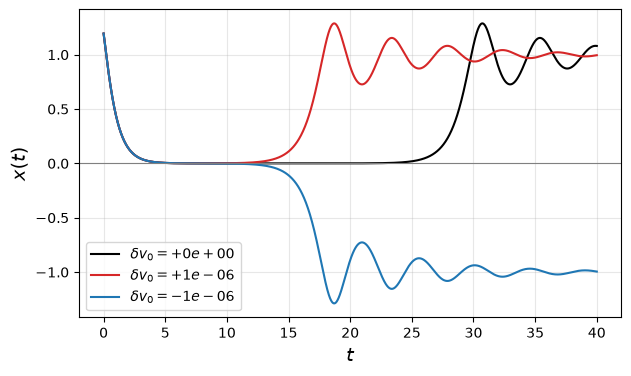

In [13]:
# Tocka na meji bazenov (stabilna mnogoterost) + majhna motnja v v
i_m = np.argmin(np.abs(np.hypot(*veji[0]) - 1.5))
y_meja = veji[0][:, i_m]
t_r = np.linspace(0, 40, 4000)

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
for dv, c in [(0.0, "black"), (1e-6, "C3"), (-1e-6, "C0")]:
    sol = solve_ivp(rhs, (0, 40), y_meja + np.array([0.0, dv]), args=(d,), t_eval=t_r,
                    rtol=rtol, atol=atol)
    ax.plot(sol.t, sol.y[0], color=c, label=rf"$\delta v_0 = {dv:+.0e}$")
print(f"zacetna tocka na meji: ({y_meja[0]:+.4f}, {y_meja[1]:+.4f})")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("$t$", fontsize=14)
ax.set_ylabel("$x(t)$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Razmislek 3

In [14]:
# Linearni oscilator: ena sama ravnotezna tocka, paraboličen potencial
w0 = sp.symbols("omega_0", positive=True)
f_lin = sp.Matrix([v, -w0**2 * x - d_s * v])
print("ravnotezja:", sp.solve(list(f_lin), [x, v], dict=True))
print("V_lin =", sp.integrate(w0**2 * x, x))

ravnotezja: [{v: 0, x: 0}]
V_lin = omega_0**2*x**2/2
